In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import LabelEncoder


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hamxo86/student-performence-dataset")

print("Path to dataset files:", path)

100%|██████████| 516k/516k [00:00<00:00, 81.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/hamxo86/student-performence-dataset/versions/1


In [ ]:
import os
print(os.listdir(path))

['Student_Performance.csv']


In [ ]:
import pandas as pd
df=pd.read_csv(path+'/Student_Performance.csv')
df.head()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f


In [ ]:
df.tail()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
24995,12047,17,female,public,phd,1.8,55.2,yes,15-30 min,no,mixed,55.8,48.5,46.7,46.1,e
24996,1102,16,female,private,diploma,2.7,97.1,yes,<15 min,no,coaching,64.8,48.2,52.3,56.5,d
24997,4422,19,other,private,post graduate,1.0,63.0,yes,<15 min,no,group study,50.5,20.3,36.1,36.7,f
24998,7858,14,male,private,diploma,1.0,69.4,yes,15-30 min,yes,group study,13.0,34.2,7.3,34.1,f
24999,11621,18,other,public,no formal,0.7,60.3,yes,30-60 min,no,mixed,36.5,45.1,16.5,31.4,f


Understand Dataset

In [ ]:
print("Columns",df.columns)
print("Shape",df.shape)


Columns Index(['student_id', 'age', 'gender', 'school_type', 'parent_education',
       'study_hours', 'attendance_percentage', 'internet_access',
       'travel_time', 'extra_activities', 'study_method', 'math_score',
       'science_score', 'english_score', 'overall_score', 'final_grade'],
      dtype='object')
Shape (25000, 16)


In [ ]:
print(df.describe())
print("-"*30)
print(df.info())
print("-"*30)
print("NULL Values Sum")
print(df.isnull().sum())
print("-"*30)
print("Duplicate Values Sum")
print(df.duplicated().sum())
print("-"*30)
print("Unique Values")
print(df.nunique())

        student_id           age   study_hours  attendance_percentage  \
count  25000.00000  25000.000000  25000.000000           25000.000000   
mean    7493.04380     16.482760      4.253224              75.084084   
std     4323.56215      1.703895      2.167541              14.373171   
min        1.00000     14.000000      0.500000              50.000000   
25%     3743.75000     15.000000      2.400000              62.800000   
50%     7461.50000     16.000000      4.300000              75.100000   
75%    11252.00000     18.000000      6.100000              87.500000   
max    15000.00000     19.000000      8.000000             100.000000   

         math_score  science_score  english_score  overall_score  
count  25000.000000   25000.000000   25000.000000   25000.000000  
mean      63.785944      63.745320      63.681948      64.006172  
std       20.875262      20.970529      20.792693      18.932025  
min        0.000000       0.000000       0.000000      14.500000  
25%    

Categorical vaullues value count

In [ ]:

#value counting
categorical_columns = [
    "gender",
    "school_type",
    "parent_education",
    "internet_access",
    "travel_time",
    "extra_activities",
    "study_method",
    "final_grade"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


gender:
gender
other     8463
female    8290
male      8247
Name: count, dtype: int64

school_type:
school_type
private    12725
public     12275
Name: count, dtype: int64

parent_education:
parent_education
diploma          4314
high school      4205
post graduate    4196
graduate         4127
no formal        4079
phd              4079
Name: count, dtype: int64

internet_access:
internet_access
yes    21227
no      3773
Name: count, dtype: int64

travel_time:
travel_time
15-30 min    6362
30-60 min    6345
>60 min      6166
<15 min      6127
Name: count, dtype: int64

extra_activities:
extra_activities
yes    12500
no     12500
Name: count, dtype: int64

study_method:
study_method
mixed            4341
textbook         4239
notes            4165
online videos    4139
group study      4090
coaching         4026
Name: count, dtype: int64

final_grade:
final_grade
d    6311
c    6161
e    5672
f    2955
b    2696
a    1205
Name: count, dtype: int64


In [ ]:
#student id duplicates
print(df["student_id"].nunique())
print("student id duplicates")
print(df["student_id"].duplicated().sum())
id_counts = df["student_id"].value_counts()

print("Students appearing more than once:")
print(id_counts[id_counts > 1])

15000
student id duplicates
10000
Students appearing more than once:
student_id
4781     7
14061    6
7100     6
3720     6
11619    6
        ..
25       2
26       2
27       2
14942    2
14994    2
Name: count, Length: 7265, dtype: int64


In [ ]:
#dislaying the record which appear 7 tmes
student_records = df[df["student_id"] == 4781]

print(student_records.to_string(index=False))
print(df.columns.tolist())


 student_id  age gender school_type parent_education  study_hours  attendance_percentage internet_access travel_time extra_activities study_method  math_score  science_score  english_score  overall_score final_grade
       4781   19   male      public          diploma          5.8                   55.3             yes     >60 min              yes     textbook        65.6           79.8           82.0           68.4           d
       4781   19   male      public          diploma          5.8                   55.3             yes     >60 min              yes     textbook        65.6           79.8           82.0           68.4           d
       4781   19   male      public          diploma          5.8                   55.3             yes     >60 min              yes     textbook        65.6           79.8           82.0           68.4           d
       4781   19   male      public          diploma          5.8                   55.3             yes     >60 min              yes   

Data cleaning and preprocessing

There is No Missing values so No need to do the missing

In [ ]:
#remving duplicated elements

original_rows = len(df)

df = df.drop_duplicates()
#checking duplicates are removed
print("Original rows:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Rows removed:", original_rows - len(df))
print("Remaining exact duplicates:", df.duplicated().sum())

Original rows: 25000
Rows after removing duplicates: 15000
Rows removed: 10000
Remaining exact duplicates: 0


In [ ]:
#saving the cleaned data set
df.to_csv("student_performance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [ ]:
#detecting outliners
numerical_columns = [
    "age",
    "study_hours",
    "attendance_percentage",
    "math_score",
    "science_score",
    "english_score",
    "overall_score"
]

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound)
        | (df[col] > upper_bound)
    ]

    print(
        f"{col}: {len(outliers)} potential outliers"
    )

age: 0 potential outliers
study_hours: 0 potential outliers
attendance_percentage: 0 potential outliers
math_score: 5 potential outliers
science_score: 4 potential outliers
english_score: 2 potential outliers
overall_score: 0 potential outliers


In [ ]:
numerical_columns = [
    "age",
    "study_hours",
    "attendance_percentage",
    "math_score",
    "science_score",
    "english_score",
    "overall_score"
]

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outliers = df.loc[
        outlier_mask,
        ["student_id", col]
    ]

    if not outliers.empty:
        print(f"\nOutliers in {col}:")
        print(outliers.to_string(index=False))


Outliers in math_score:
 student_id  math_score
       3902         0.0
      10777         0.0
      11558         0.0
      13636         0.0
      13745         0.0

Outliers in science_score:
 student_id  science_score
        557            0.0
       1663            0.0
       8379            0.0
      12850            0.0

Outliers in english_score:
 student_id  english_score
       4041            0.0
      10227            0.0


In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("Unique student IDs:", df["student_id"].nunique())

print(
    "Repeated student ID occurrences:",
    df["student_id"].duplicated().sum()
)

Dataset shape: (15000, 16)

Missing values: 0
Exact duplicate rows: 0
Unique student IDs: 15000
Repeated student ID occurrences: 0


In [ ]:
#chekong the overall score
df["calculated_overall"] = df[
    ["math_score", "science_score", "english_score"]
].mean(axis=1)

df["overall_difference"] = (
    df["overall_score"]
    - df["calculated_overall"]
)

print(df[
    [
        "math_score",
        "science_score",
        "english_score",
        "overall_score",
        "calculated_overall",
        "overall_difference"
    ]
].head(10))

   math_score  science_score  english_score  overall_score  \
0        42.7           55.4           57.0           53.1   
1        57.6           68.8           64.8           61.3   
2        84.8           95.0           79.2           89.6   
3        44.4           27.5           54.7           41.6   
4         8.9           32.7           30.0           25.4   
5        51.5           78.3           63.9           63.5   
6        41.9           29.4           39.2           39.1   
7        56.7           60.1           53.4           69.6   
8        54.1           59.5           38.3           55.2   
9        71.9           70.4           81.3           69.6   

   calculated_overall  overall_difference  
0           51.700000            1.400000  
1           63.733333           -2.433333  
2           86.333333            3.266667  
3           42.200000           -0.600000  
4           23.866667            1.533333  
5           64.566667           -1.066667  
6        

# EDA  
Exploratory data analysis


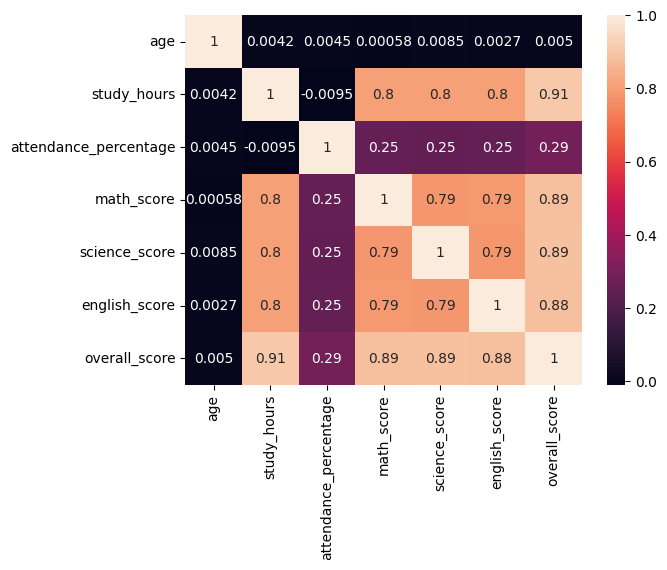

In [ ]:
#heatmap for numerical cols
sns.heatmap(df[numerical_columns].corr(), annot=True)
plt.show()

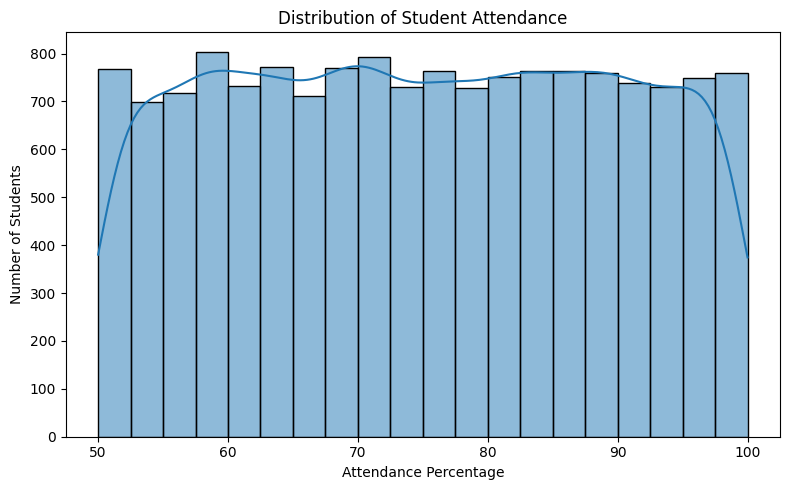

In [ ]:
#distibution of attendence
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="attendance_percentage",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

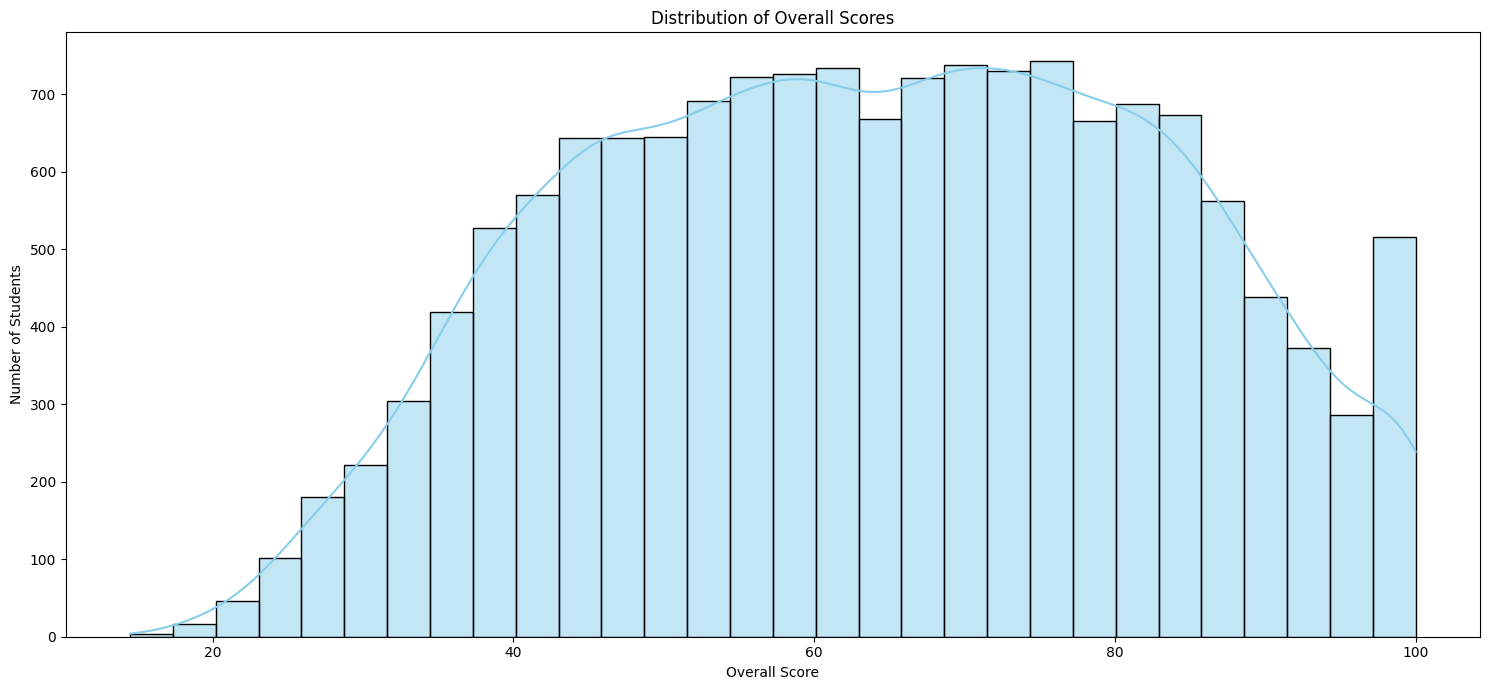

In [ ]:
#overall socre disribution
plt.figure(figsize=(15, 7))
sns.histplot(
    data=df,
    x="overall_score",
    bins=30,
    kde=True,
    color="skyblue"
)
plt.title("Distribution of Overall Scores")
plt.xlabel("Overall Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

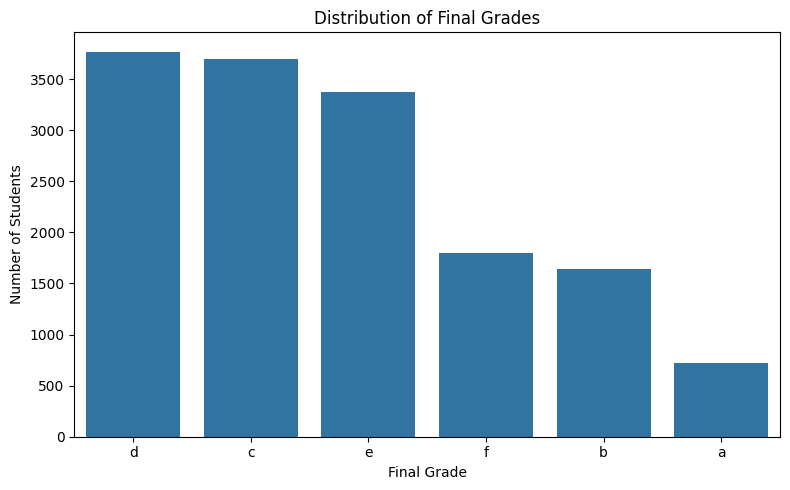

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="final_grade",
    order=df["final_grade"].value_counts().index
)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

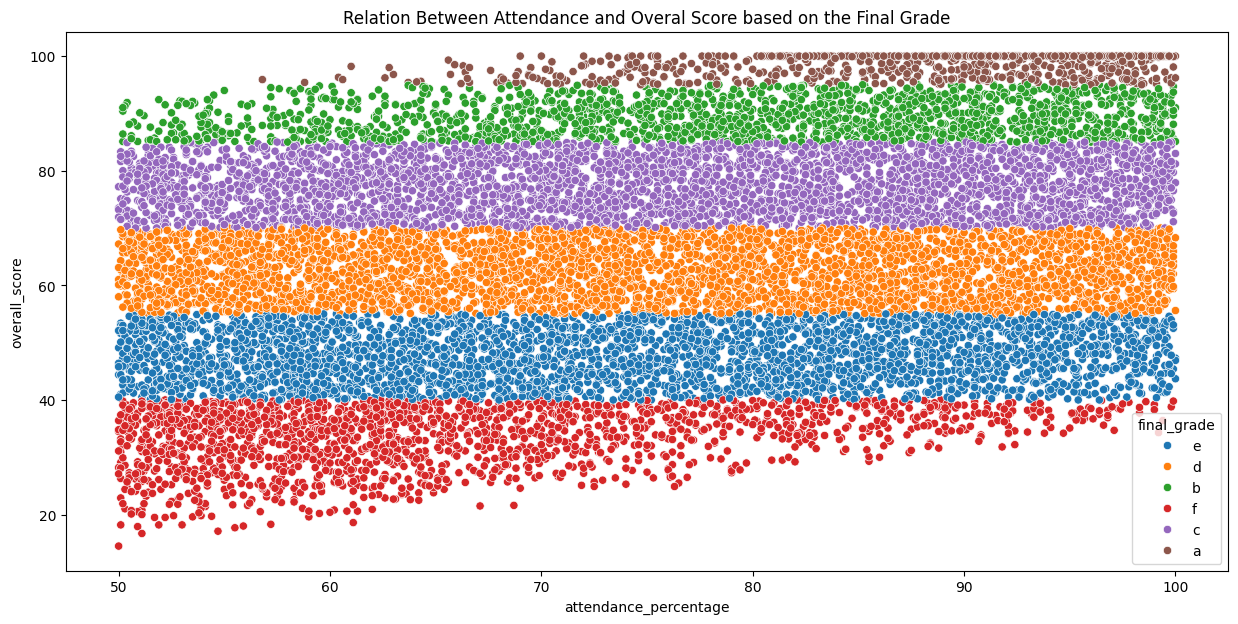

In [ ]:
#relationship between attendance and overall scores.
plt.figure(figsize=(15, 7))
plt.title("Relation Between Attendance and Overal Score based on the Final Grade")
sns.scatterplot(x="attendance_percentage",y="overall_score",data=df,hue="final_grade")
plt.show()

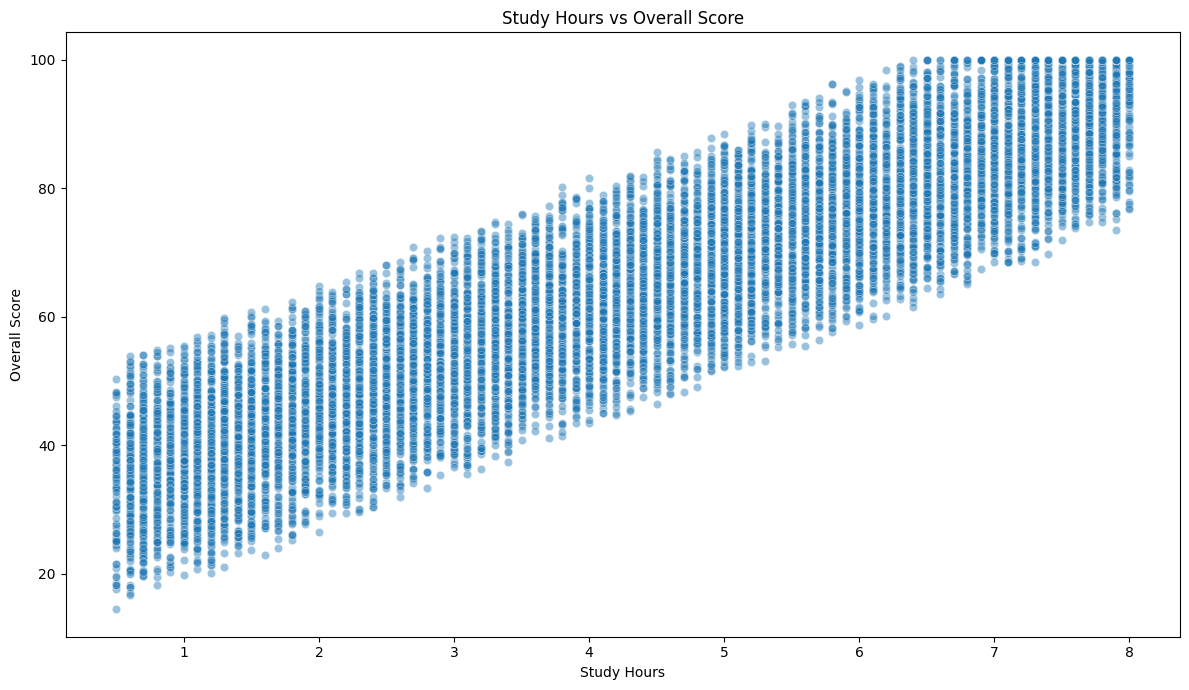

In [ ]:
#relation between study hours and overall score
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="study_hours",
    y="overall_score",
    alpha=0.45
)

plt.title("Study Hours vs Overall Score")
plt.xlabel("Study Hours")
plt.ylabel("Overall Score")

plt.tight_layout()
plt.show()

Categorical plotting

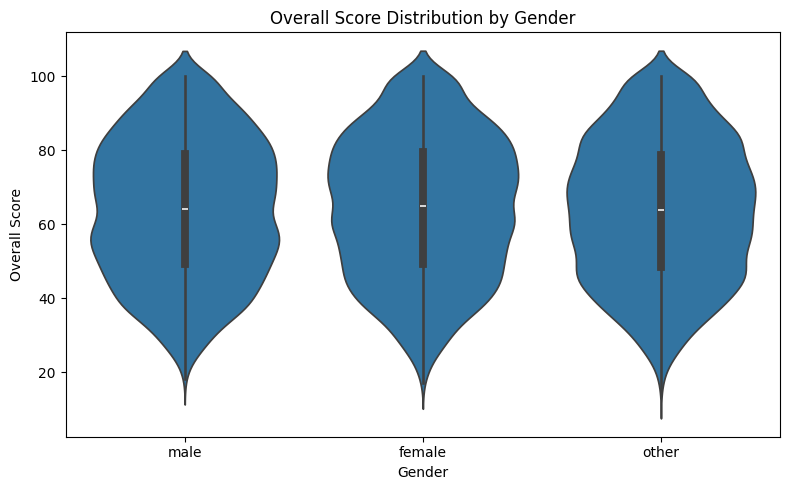

In [ ]:
#Gender versus overall score
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="gender",
    y="overall_score"
)

plt.title("Overall Score Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Overall Score")

plt.tight_layout()
plt.show()


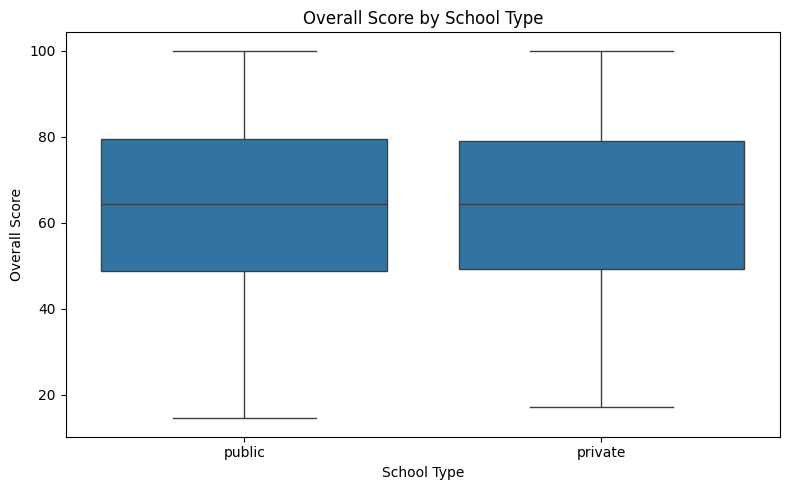

In [ ]:
#School type versus overall score
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="school_type",
    y="overall_score"
)

plt.title("Overall Score by School Type")
plt.xlabel("School Type")
plt.ylabel("Overall Score")

plt.tight_layout()
plt.show()

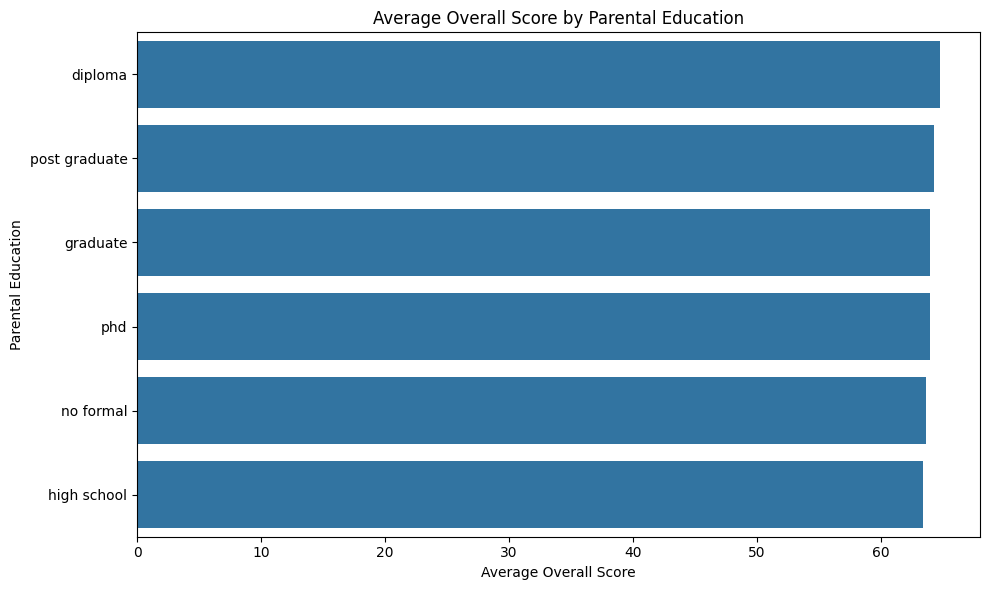

  parent_education  overall_score
0          diploma      64.773382
1    post graduate      64.303748
2         graduate      63.946393
3              phd      63.938417
4        no formal      63.653006
5      high school      63.445972


In [ ]:
#Parental education versus overall score
parent_summary = (
    df.groupby("parent_education", observed=True)
    ["overall_score"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=parent_summary,
    x="overall_score",
    y="parent_education"
)

plt.title("Average Overall Score by Parental Education")
plt.xlabel("Average Overall Score")
plt.ylabel("Parental Education")

plt.tight_layout()
plt.show()

print(parent_summary)

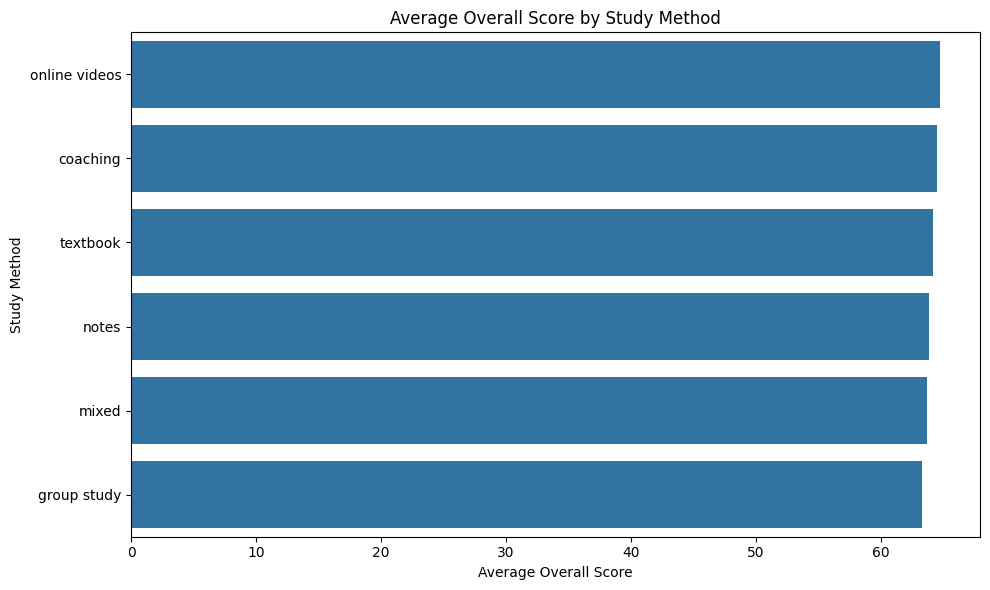

    study_method  overall_score
0  online videos      64.683063
1       coaching      64.476259
2       textbook      64.190024
3          notes      63.858012
4          mixed      63.653574
5    group study      63.251287


In [ ]:
#Study method versus overall score
study_method_summary = (
    df.groupby("study_method", observed=True)
    ["overall_score"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=study_method_summary,
    x="overall_score",
    y="study_method"
)

plt.title("Average Overall Score by Study Method")
plt.xlabel("Average Overall Score")
plt.ylabel("Study Method")

plt.tight_layout()
plt.show()

print(study_method_summary)

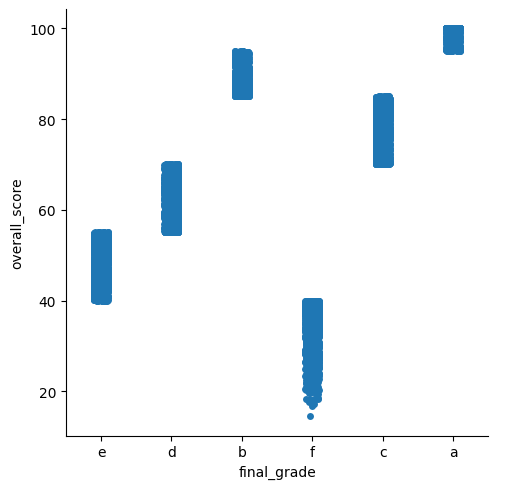

In [ ]:
#cat plot of raltion with final grade and overall_score
sns.catplot(data=df, x="final_grade", y="overall_score")
plt.show()

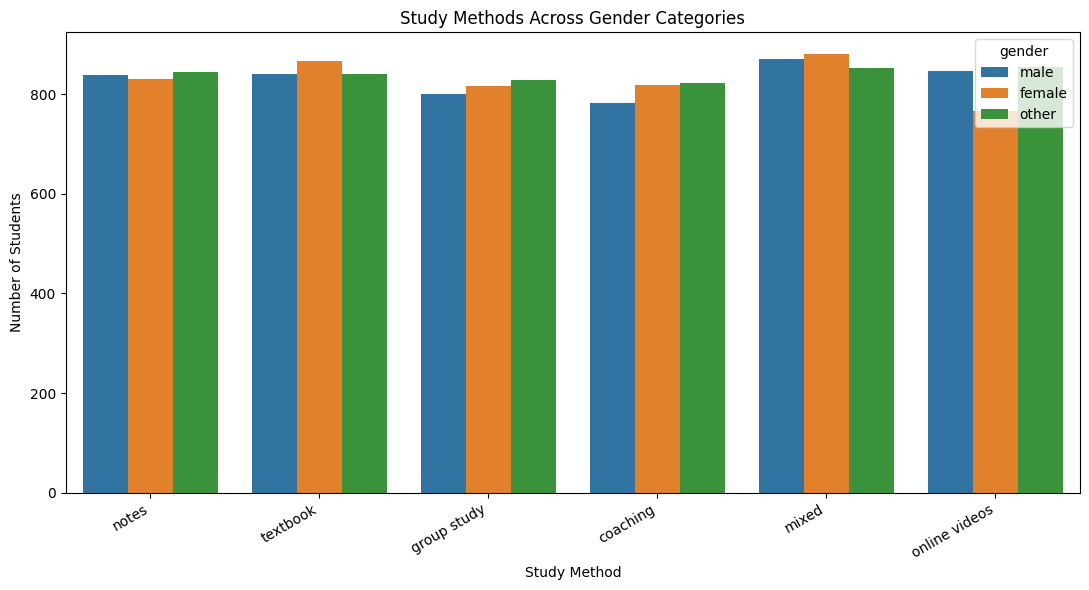

In [ ]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x="study_method",
    hue="gender"
)

plt.title("Study Methods Across Gender Categories")
plt.xlabel("Study Method")
plt.ylabel("Number of Students")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

feature enginerring


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
df_model = df.drop(
    columns=[
        "calculated_overall",
        "overall_difference"
    ],
    errors="ignore"
).copy()

target = "final_grade"
#this may lead to predict the answer
exclude_columns = [
    "student_id",
    "final_grade",
    "overall_score",
    "travel_time"
]
#input
X = df_model.drop(
    columns=exclude_columns,
    errors="ignore"
)

# taget col
y = df_model[target]

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(sorted(y.dropna().unique()))

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (15000, 18)

Columns:
['student_id', 'age', 'gender', 'school_type', 'parent_education', 'study_hours', 'attendance_percentage', 'internet_access', 'travel_time', 'extra_activities', 'study_method', 'math_score', 'science_score', 'english_score', 'overall_score', 'final_grade', 'calculated_overall', 'overall_difference']

Feature matrix shape: (15000, 12)
Target shape: (15000,)

Input features:
['age', 'gender', 'school_type', 'parent_education', 'study_hours', 'attendance_percentage', 'internet_access', 'extra_activities', 'study_method', 'math_score', 'science_score', 'english_score']

Target classes:
['a', 'b', 'c', 'd', 'e', 'f']

Target distribution:
final_grade
d    3770
c    3697
e    3378
f    1796
b    1638
a     721
Name: count, dtype: int64


In [ ]:
X.head()

,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,extra_activities,study_method,math_score,science_score,english_score
0,14,male,public,post graduate,3.1,84.3,yes,yes,notes,42.7,55.4,57.0
1,18,female,public,graduate,3.7,87.8,yes,no,textbook,57.6,68.8,64.8
2,17,female,private,post graduate,7.9,65.5,no,no,notes,84.8,95.0,79.2
3,16,other,public,high school,1.1,58.1,no,no,notes,44.4,27.5,54.7
4,16,female,public,high school,1.3,61.0,yes,yes,group study,8.9,32.7,30.0


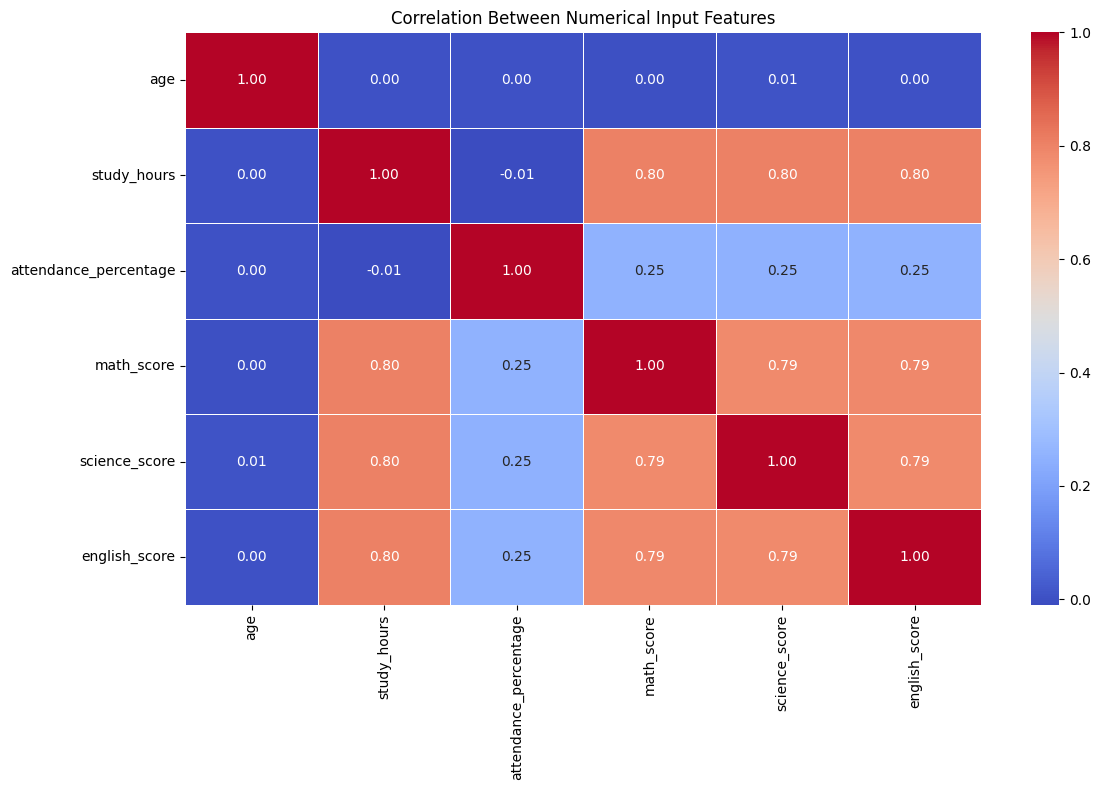

In [ ]:

numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
plt.figure(figsize=(12, 8))
sns.heatmap(
    X[numerical_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Input Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 12000
Testing samples: 3000

Training class distribution:
final_grade
d    0.254
c    0.245
e    0.226
f    0.117
b    0.110
a    0.047
Name: proportion, dtype: float64

Testing class distribution:
final_grade
c    0.251
d    0.240
e    0.223
f    0.129
b    0.105
a    0.052
Name: proportion, dtype: float64


preprocessing the features

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler,LabelEncoder




numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            LabelEncoder(),
            categorical_features
        )
    ]
)

print("\nPreprocessor created successfully.")

Numerical features: ['age', 'study_hours', 'attendance_percentage', 'math_score', 'science_score', 'english_score']
Categorical features: ['gender', 'school_type', 'parent_education', 'internet_access', 'extra_activities', 'study_method']

Preprocessor created successfully.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Redefine preprocessor with OneHotEncoder instead of LabelEncoder
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ]
)

preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

X_train_processed = preprocessing_pipeline.fit_transform(
    X_train,
    y_train
)

X_test_processed = preprocessing_pipeline.transform(
    X_test
)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (12000, 12)
Processed training shape: (12000, 27)
Original testing shape: (3000, 12)
Processed testing shape: (3000, 27)


In [ ]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=preprocessing_pipeline.named_steps[
        "preprocessor"
    ].get_feature_names_out()
)

X_train_processed_df.head()

,num__age,num__study_hours,num__attendance_percentage,num__math_score,num__science_score,num__english_score,cat__gender_female,cat__gender_male,cat__gender_other,cat__school_type_private,...,cat__internet_access_no,cat__internet_access_yes,cat__extra_activities_no,cat__extra_activities_yes,cat__study_method_coaching,cat__study_method_group study,cat__study_method_mixed,cat__study_method_notes,cat__study_method_online videos,cat__study_method_textbook
0,-0.277408,-1.224581,-0.110828,-0.231457,-0.288624,-0.515428,0.0,1.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-1.448727,1.536420,1.009645,1.728829,1.086107,1.746376,0.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.277408,-1.592714,-1.008598,-2.062336,-1.143058,-1.083285,0.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.308252,0.892187,-0.820693,0.012980,0.207806,0.370044,0.0,0.0,1.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.448727,1.490404,1.030523,1.321435,1.200668,1.221830,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier

models = {
    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

print("Models created:", len(models))

for model_name in models:
    print(model_name)

Models created: 7
Dummy Classifier
Logistic Regression
KNN
Decision Tree
Random Forest
SVM
Gradient Boosting


In [ ]:


import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
    })

    trained_models[model_name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.7580     0.7633  0.7361    0.7459
  Gradient Boosting    0.7533     0.7546  0.7404    0.7456
                SVM    0.7540     0.7542  0.7301    0.7385
      Random Forest    0.7500     0.7535  0.7164    0.7303
      Decision Tree    0.6557     0.6582  0.6455    0.6497
                KNN    0.6453     0.6275  0.6161    0.6208
   Dummy Classifier    0.2403     0.0401  0.1667    0.0646


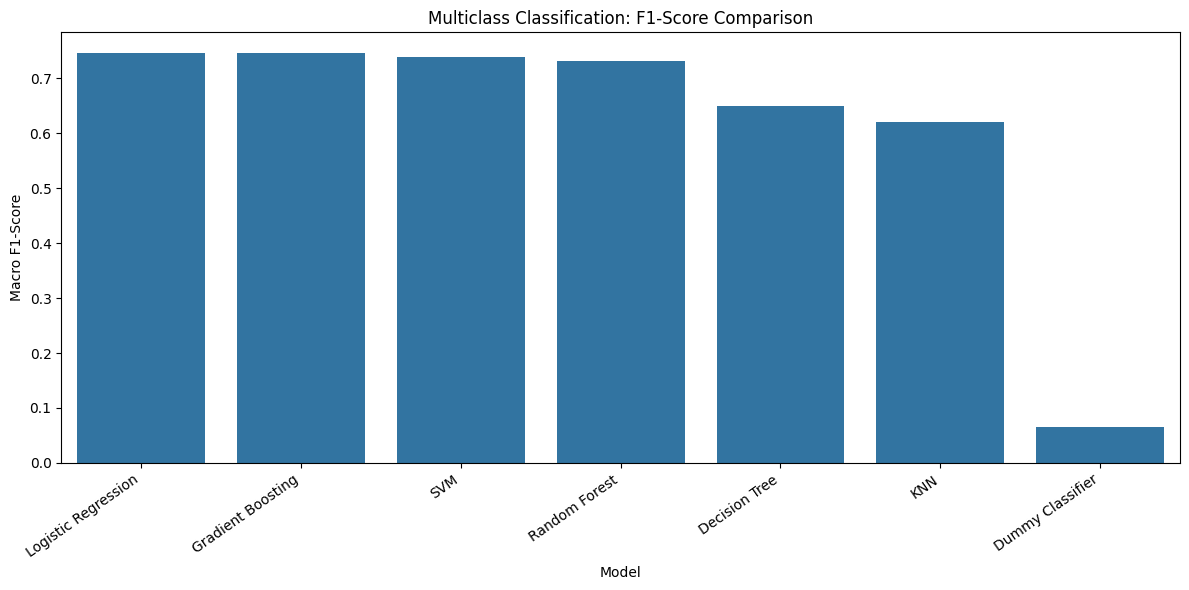

In [ ]:
# Step 12: Compare model performance

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Multiclass Classification: F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Macro F1-Score")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


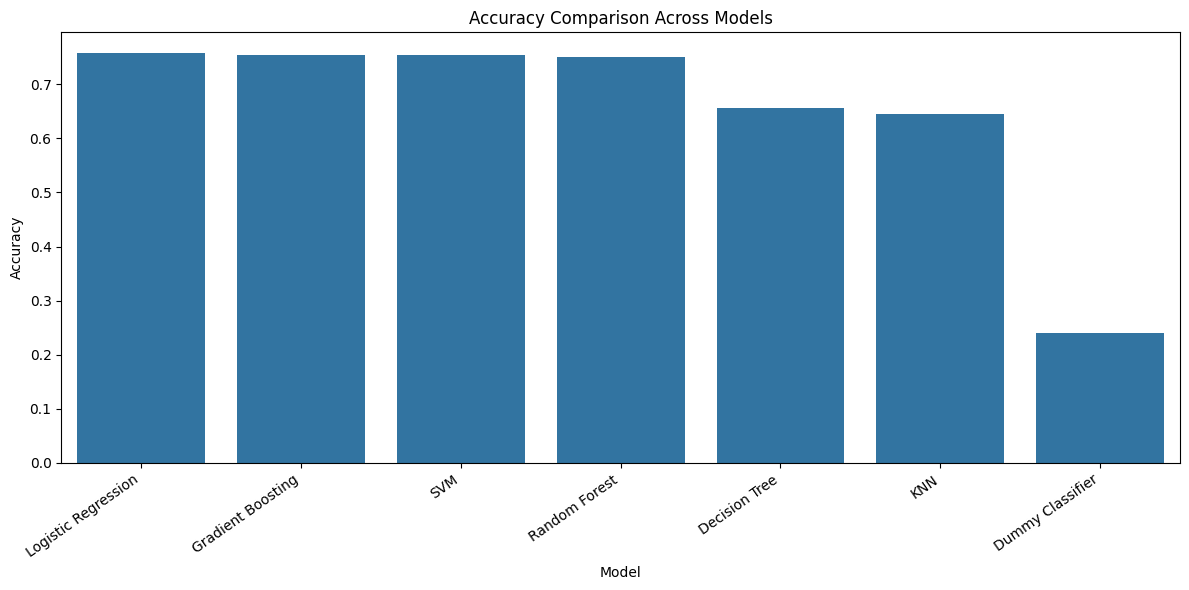

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison Across Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Step 13: Select the best-performing model

from sklearn.metrics import classification_report

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

y_pred_best = best_model.predict(X_test)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_best,
        zero_division=0
    )
)

Best model: Logistic Regression

Classification Report:

              precision    recall  f1-score   support

           a       0.83      0.62      0.71       155
           b       0.61      0.72      0.66       314
           c       0.79      0.76      0.78       752
           d       0.76      0.77      0.77       721
           e       0.75      0.79      0.77       670
           f       0.83      0.76      0.79       388

    accuracy                           0.76      3000
   macro avg       0.76      0.74      0.75      3000
weighted avg       0.76      0.76      0.76      3000



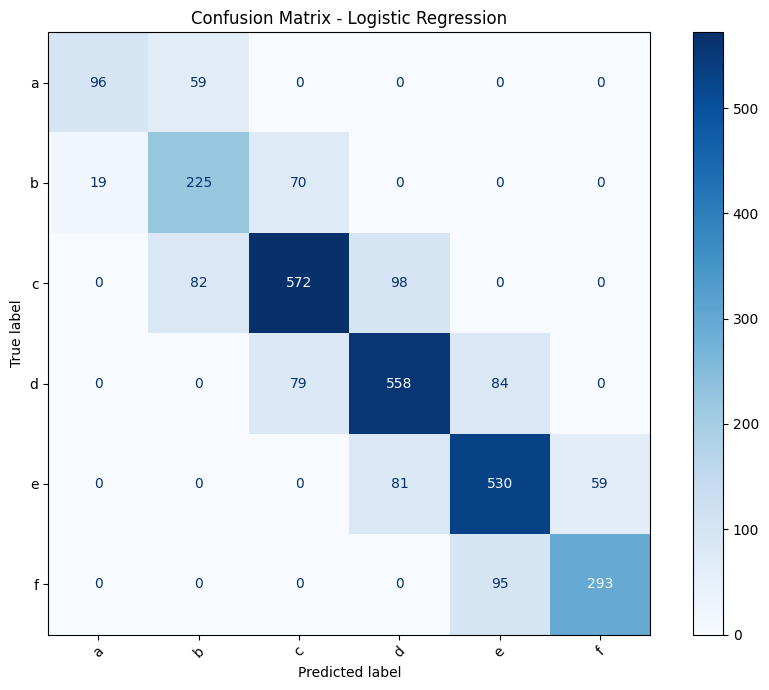

In [ ]:
# Step 14: Confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

class_labels = best_model.named_steps[
    "classifier"
].classes_

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=class_labels,
    display_labels=class_labels,
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

                            Feature  Importance
                   num__study_hours    0.220809
                 num__science_score    0.170697
                    num__math_score    0.169154
                 num__english_score    0.166368
         num__attendance_percentage    0.090036
                           num__age    0.030124
                  cat__gender_other    0.008623
                 cat__gender_female    0.008611
                   cat__gender_male    0.008547
            cat__school_type_public    0.008005
           cat__school_type_private    0.007936
  cat__parent_education_high school    0.007655
cat__parent_education_post graduate    0.007528
          cat__extra_activities_yes    0.007521
     cat__parent_education_graduate    0.007430
           cat__extra_activities_no    0.007330
    cat__parent_education_no formal    0.007319
      cat__parent_education_diploma    0.007312
    cat__study_method_online videos    0.007252
         cat__study_method_textbook    0

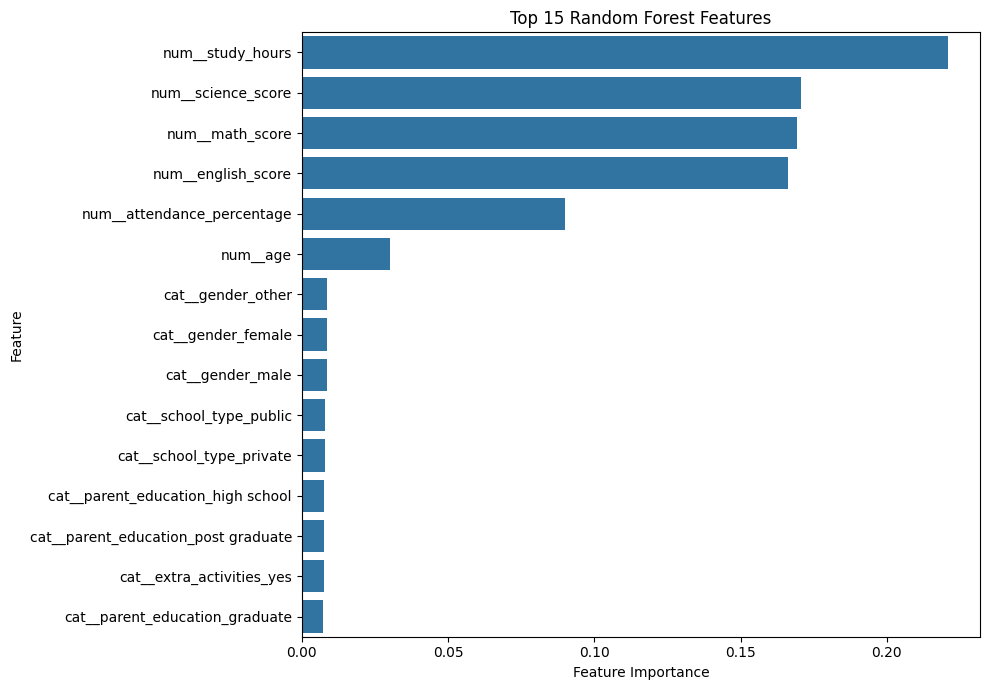

In [ ]:


rf_pipeline = trained_models["Random Forest"]

rf_preprocessor = rf_pipeline.named_steps["preprocessor"]

rf_model = rf_pipeline.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print(importance_df.to_string(index=False))
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
# Step 16: GridSearchCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_pipeline = trained_models["Random Forest"]

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1:")
print(grid_search.best_score_)


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best cross-validation F1:
0.7410948665189159


In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_tuned))

print(
    "Test Macro F1:",
    f1_score(
        y_test,
        y_pred_tuned,
        average="macro",
        zero_division=0
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

Test Accuracy: 0.7546666666666667
Test Macro F1: 0.7384767583836966

Classification Report:
              precision    recall  f1-score   support

           a       0.85      0.57      0.68       155
           b       0.62      0.68      0.65       314
           c       0.78      0.77      0.78       752
           d       0.74      0.79      0.76       721
           e       0.75      0.78      0.76       670
           f       0.84      0.74      0.79       388

    accuracy                           0.75      3000
   macro avg       0.76      0.72      0.74      3000
weighted avg       0.76      0.75      0.75      3000



In [ ]:
%pip install xgboost


Grade classes: ['a' 'b' 'c' 'd' 'e' 'f']

XGBoost Performance
----------------------------------------
Accuracy: 0.7453
Macro Precision: 0.7444
Macro Recall: 0.7325
Macro F1: 0.7368

Classification Report:
              precision    recall  f1-score   support

           a       0.79      0.66      0.72       155
           b       0.59      0.68      0.64       314
           c       0.77      0.73      0.75       752
           d       0.74      0.76      0.75       721
           e       0.76      0.77      0.76       670
           f       0.81      0.80      0.80       388

    accuracy                           0.75      3000
   macro avg       0.74      0.73      0.74      3000
weighted avg       0.75      0.75      0.75      3000



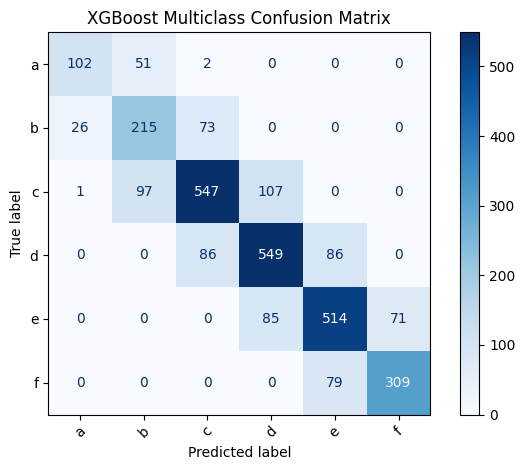

In [ ]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

# 1. Encode target labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Grade classes:", label_encoder.classes_)

# 2. Define XGBoost
xgb_model = XGBClassifier(
    objective="multi:softprob",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)

# 3. Create pipeline
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_model)
    ]
)

# 4. Train
xgb_pipeline.fit(X_train, y_train_encoded)

# 5. Predict
y_pred_encoded = xgb_pipeline.predict(X_test).astype(int)

# Convert predictions to original grade labels
y_pred_grades = label_encoder.inverse_transform(y_pred_encoded)

# 6. Evaluation
print("\nXGBoost Performance")
print("-" * 40)

print(
    "Accuracy:",
    round(accuracy_score(y_test_encoded, y_pred_encoded), 4)
)

print(
    "Macro Precision:",
    round(
        precision_score(
            y_test_encoded,
            y_pred_encoded,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "Macro Recall:",
    round(
        recall_score(
            y_test_encoded,
            y_pred_encoded,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test_encoded,
            y_pred_encoded,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        y_pred_encoded,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_.astype(str),
        zero_division=0
    )
)

# 7. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    y_pred_encoded,
    labels=range(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost Multiclass Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
Test the model using random test cases

import random

# Selecting 5 random row indexes
random_indexes = random.sample(range(len(X_test)), 5)

for i in random_indexes:
    # Get student details
    student = X_test.iloc[[i]]

    # Predict the grade
    prediction = xgb_pipeline.predict(student)

    # Convert prediction to original grade
    predicted_grade = label_encoder.inverse_transform(prediction)

    print("Test Case:", i + 1)
    print("Student Details:")
    print(student)
    print("Predicted Grade:", predicted_grade[0])
    print("-" * 40)

Enter the student's details:
----------------------------------------
age (number): 19
Possible values for gender: ['male', 'female', 'other']
gender: Male
Possible values for school_type: ['public', 'private']
school_type: Private
Possible values for parent_education: ['post graduate', 'graduate', 'high school', 'no formal', 'diploma', 'phd']
parent_education: high schoo;
study_hours (number): 5
attendance_percentage (number): 78
Possible values for internet_access: ['yes', 'no']
internet_access: no
Possible values for extra_activities: ['yes', 'no']
extra_activities: no
Possible values for study_method: ['notes', 'textbook', 'group study', 'coaching', 'mixed', 'online videos']
study_method: notes
math_score (number): 89
science_score (number): 87
english_score (number): 78

STUDENT PERFORMANCE PREDICTION
Predicted final grade: c

Prediction probabilities:
a: 0.00%
b: 1.26%
c: 97.40%
d: 1.32%
e: 0.01%
f: 0.00%
